# ¿Cuándo conviene reentrenar el modelo de Machine Learning?

**Consumo 5 · Consultas ad-hoc y exploración.** El modelo de intensidad del consumo 4 aprende de los
testimonios ciudadanos de LastQuake (ClickHouse), y esos solo existen para los sismos que la gente
sintió y reportó. El **catálogo USGS del Lakehouse** es el registro instrumental completo: sirve de
referencia para saber qué sismos ocurrieron que el modelo nunca vio.

**Preguntas que responde:** ¿qué versión del catálogo existía cuando se entrenó cada versión del
modelo?, ¿qué parte de la sismicidad real queda dentro de lo que el modelo conoce? y ¿llegaron sismos
que justifiquen reentrenarlo?

| Fuente | Qué aporta |
| --- | --- |
| `datos/modelos/intensidad_ems98/*.json` | Cada versión del modelo: cuándo se entrenó, su corte de datos y su dominio (rango de magnitud, profundidad y distancia de sus testimonios) |
| **PyIceberg** (*Time Travel*) | El catálogo tal como estaba en el instante de cada entrenamiento (`snapshot_as_of_timestamp`) |
| **DuckDB** | Comparar esa versión del catálogo con la vigente y medir la cobertura del dominio |
| API del consumo 4 | Su monitoreo con los testimonios llegados después del corte (`/api/modelo/evaluacion`) |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.patches import Rectangle

import conexiones as cx

versiones = cx.versiones_modelo()
if not versiones:
    raise RuntimeError("No hay versiones del modelo en datos/modelos/intensidad_ems98/. Entrénenlo con "
                       "python consumo/api_ml/entrenar.py o POST /api/modelo/reentrenar (DEMO.md, sección 12).")

pd.DataFrame([{"version": v["version"], "entrenado_utc": v["entrenado_utc"], "algoritmo": v["algoritmo"],
               "testimonios": v["corte_datos"]["testimonios"], "sismos": v["corte_datos"]["sismos"],
               "corte_datos_utc": v["corte_datos"]["hasta_utc"][:19],
               "magnitud": "M{:g}–{:g}".format(*v["dominio"]["magnitud"]),
               "profundidad": "{:g}–{:g} km".format(*v["dominio"]["profundidad_km"]),
               "mae_validacion": v["validacion"]["metricas"][v["algoritmo"]]["mae"]} for v in versiones])

,version,entrenado_utc,algoritmo,testimonios,sismos,corte_datos_utc,magnitud,profundidad,mae_validacion
0,v20261104T182408,2026-11-04T18:24:08+00:00,ecuacion_atenuacion,2444,325,2026-11-03 02:18:46,M2.5–6.9,4–207 km,0.988


## 1. Time Travel: el catálogo que existía cuando se entrenó cada versión

Iceberg guarda la hora de cada snapshot, así que se puede preguntar qué versión del catálogo estaba
vigente en cualquier instante. Esto deja auditado con qué corte del catálogo convivía cada modelo:
si el informe de un modelo se cuestiona, se vuelve a leer exactamente ese catálogo.

In [2]:
cat = cx.catalogo()
silver = cat.load_table(cx.SILVER_TABLA)
vigente = silver.current_snapshot()


def snapshot_en(instante_utc: str):
    return silver.snapshot_as_of_timestamp(int(pd.Timestamp(instante_utc).timestamp() * 1000))


auditoria = []
for v in versiones:
    snap = snapshot_en(v["entrenado_utc"])
    auditoria.append({"version_modelo": v["version"], "entrenado_utc": v["entrenado_utc"],
                      "snapshot_catalogo": snap.snapshot_id if snap else None,
                      "sismos_en_el_catalogo": int(snap.summary["total-records"]) if snap else 0,
                      "sismos_hoy": int(vigente.summary["total-records"])})
pd.DataFrame(auditoria)

,version_modelo,entrenado_utc,snapshot_catalogo,sismos_en_el_catalogo,sismos_hoy
0,v20261104T182408,2026-11-04T18:24:08+00:00,7273476244542248163,647,653


## 2. Sismos que llegaron al catálogo después del último entrenamiento

Se compara el catálogo del instante del entrenamiento con el vigente. Cada sismo nuevo se revisa
contra el **dominio** del modelo, con la misma tolerancia que usa la API para avisar *fuera de
rango*: magnitud hasta 0,3 sobre la mayor vista y profundidad hasta 10 km fuera del rango visto.

In [3]:
modelo = versiones[-1]
dominio = modelo["dominio"]
M_MIN, M_MAX = dominio["magnitud"][0] - 0.3, dominio["magnitud"][1] + 0.3
H_MIN, H_MAX = dominio["profundidad_km"][0] - 10, dominio["profundidad_km"][1] + 10
corte = pd.Timestamp(modelo["corte_datos"]["hasta_utc"], tz="UTC")

con = silver.scan().to_duckdb(table_name="sismos")
fuera = f"""CASE WHEN magnitud > {M_MAX} THEN 'magnitud mayor a la vista'
                 WHEN profundidad_km > {H_MAX} THEN 'más profundo que lo visto'
                 WHEN profundidad_km < {H_MIN} THEN 'más superficial que lo visto'
                 ELSE NULL END"""
snap = snapshot_en(modelo["entrenado_utc"])
if snap is not None:
    silver.scan(snapshot_id=snap.snapshot_id).to_duckdb(table_name="sismos_al_entrenar", connection=con)
else:                                   # el modelo es anterior a la primera carga del catálogo
    con.sql("CREATE TABLE sismos_al_entrenar AS SELECT * FROM sismos LIMIT 0")

nuevos = con.sql(f"""
    SELECT tiempo_utc, magnitud, round(profundidad_km) AS profundidad_km, lugar,
           tiempo_utc > TIMESTAMPTZ '{corte.isoformat()}' AS despues_del_corte,
           coalesce({fuera}, 'dentro del dominio') AS frente_al_modelo, event_id
    FROM sismos ANTI JOIN sismos_al_entrenar USING (event_id)
    ORDER BY tiempo_utc
""").df()
print(f"Modelo {modelo['version']} (entrenado el {modelo['entrenado_utc'][:16]} UTC, testimonios hasta el "
      f"{corte:%d-%m-%Y %H:%M} UTC): {len(nuevos)} sismos nuevos en el catálogo desde entonces")
nuevos

Modelo v20261104T182408 (entrenado el 2026-11-04T18:24 UTC, testimonios hasta el 03-11-2026 02:18 UTC): 6 sismos nuevos en el catálogo desde entonces


,tiempo_utc,magnitud,profundidad_km,lugar,despues_del_corte,frente_al_modelo,event_id
0,2026-11-01 01:24:52.448+00:00,4.5,120.0,"55 km SSW of Ollagüe, Chile",False,dentro del dominio,us7000tuly
1,2026-11-01 05:31:54.598+00:00,4.8,202.0,"71 km NNW of San Antonio de los Cobres, Argentina",False,dentro del dominio,us7000tumy
2,2026-11-01 18:42:03.372+00:00,4.1,117.0,"70 km W of Ollagüe, Chile",False,dentro del dominio,us7000tuqw
3,2026-11-01 23:18:05.811+00:00,4.5,244.0,"86 km WNW of Abra Pampa, Argentina",False,más profundo que lo visto,us7000tus5
4,2026-11-03 01:41:27.095+00:00,4.3,107.0,"25 km NNE of Camiña, Chile",False,dentro del dominio,us7000tv27
5,2026-11-03 14:23:00.160+00:00,4.1,119.0,"57 km SW of Ollagüe, Chile",True,dentro del dominio,us7000tv5q


## 3. ¿Qué parte de la sismicidad real cubre el modelo?

El rectángulo es lo que el modelo vio al entrenar (magnitud y profundidad de sus testimonios). Cada
punto es un sismo del catálogo: los que caen fuera son escenarios donde el modelo **extrapola**, y
la API responde con la ecuación de atenuación y un aviso.

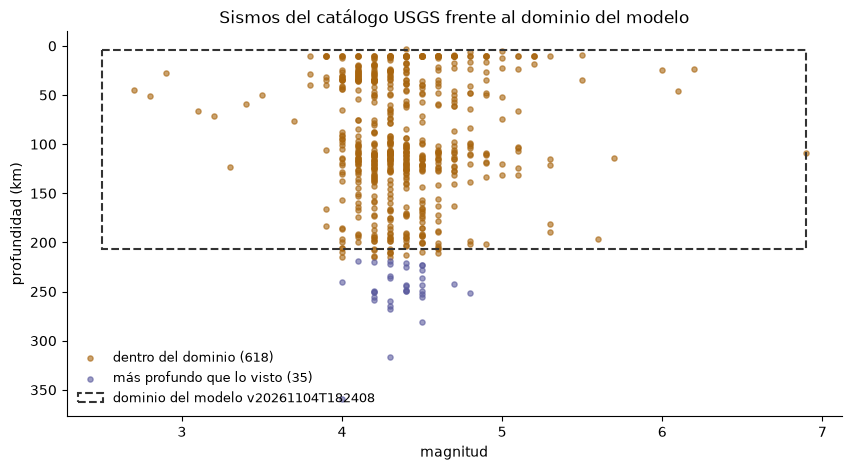

,sismos,dentro_del_dominio,pct_cubierto
macrozona,,,
Norte Grande,396,361,91.2
Norte Chico,145,145,100.0
Centro,68,68,100.0
Sur,36,36,100.0
Austral,8,8,100.0


In [4]:
sismos = con.sql(f"""SELECT magnitud, profundidad_km, {cx.sql_macrozona()} AS macrozona,
                            coalesce({fuera}, 'dentro del dominio') AS frente_al_modelo FROM sismos""").df()
fig, ax = plt.subplots(figsize=(10, 5))
for estado, color in (("dentro del dominio", "#a8650f"), ("más profundo que lo visto", "#5b5b9e"),
                      ("magnitud mayor a la vista", "#c0392b"), ("más superficial que lo visto", "#2c7fb8")):
    grupo = sismos[sismos.frente_al_modelo == estado]
    if len(grupo):
        ax.scatter(grupo.magnitud, grupo.profundidad_km, s=14, color=color, alpha=0.6, label=f"{estado} ({len(grupo)})")
ax.add_patch(Rectangle((dominio["magnitud"][0], dominio["profundidad_km"][0]),
                       dominio["magnitud"][1] - dominio["magnitud"][0],
                       dominio["profundidad_km"][1] - dominio["profundidad_km"][0],
                       fill=False, lw=1.5, ls="--", color="#333", label=f"dominio del modelo {modelo['version']}"))
ax.invert_yaxis()
ax.set(xlabel="magnitud", ylabel="profundidad (km)", title="Sismos del catálogo USGS frente al dominio del modelo")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

cobertura = (sismos.assign(dentro=sismos.frente_al_modelo == "dentro del dominio")
             .groupby("macrozona", sort=False)
             .agg(sismos=("dentro", "size"), dentro_del_dominio=("dentro", "sum")))
cobertura["pct_cubierto"] = (100 * cobertura.dentro_del_dominio / cobertura.sismos).round(1)
cobertura.reindex([m[0] for m in cx.MACROZONAS]).dropna()

## 4. El monitoreo del endpoint: testimonios nuevos

La API del consumo 4 mide el error del modelo con los testimonios que llegaron a ClickHouse
después de su corte. Si no está levantada (`docker compose --profile ml up -d`), esta parte se salta.

In [5]:
try:
    evaluacion = requests.get(f"{cx.API_ML}/api/modelo/evaluacion", timeout=60).json()
except requests.RequestException as e:
    evaluacion = None
    print(f"La API de ML no responde en {cx.API_ML} ({type(e).__name__}): se decide solo con el catálogo.")
if evaluacion:
    print(f"Versión {evaluacion['version_modelo']}: {evaluacion['testimonios_nuevos']} testimonios nuevos "
          f"(entrenó con {evaluacion['entrenamiento']['testimonios']}); ¿reentrenar? {evaluacion['reentrenar']}")
    for motivo in evaluacion["motivos"]:
        print(" -", motivo)

Versión v20261104T182408: 0 testimonios nuevos (entrenó con 2444); ¿reentrenar? False
 - No hay testimonios posteriores al corte: el modelo está al día con el warehouse.


## 5. Decisión

Se junta lo que dice el catálogo con lo que dice el monitoreo. El catálogo se adelanta a los
testimonios: si ocurrió un sismo más grande o más profundo que lo que el modelo conoce, sus
testimonios llegarán a LastQuake en las horas siguientes, y ese es el momento de reentrenar.

In [6]:
posteriores = con.sql(f"""SELECT magnitud, profundidad_km, lugar, {fuera} AS motivo FROM sismos
                          WHERE tiempo_utc > TIMESTAMPTZ '{corte.isoformat()}'""").df()
sentidos = sismos[sismos.magnitud >= 4]
pct_sentidos = 100 * (sentidos.frente_al_modelo == "dentro del dominio").mean()

criterios = [
    {"criterio": "Sismos del catálogo posteriores al corte, fuera del dominio",
     "valor": int(posteriores.motivo.notna().sum()), "umbral": "≥ 1",
     "reentrenar": bool(posteriores.motivo.notna().any())},
    {"criterio": "Sismos M ≥ 4 del catálogo dentro del dominio",
     "valor": f"{pct_sentidos:.0f} %", "umbral": "< 90 %", "reentrenar": bool(pct_sentidos < 90)},
]
if evaluacion:
    nuevos_pct = evaluacion["testimonios_nuevos"] / evaluacion["entrenamiento"]["testimonios"]
    mae_nuevos = (evaluacion["metricas_nuevos"] or {}).get("mae")
    criterios += [
        {"criterio": "Testimonios nuevos desde el corte (API)", "valor": f"{100 * nuevos_pct:.0f} %",
         "umbral": "≥ 25 %", "reentrenar": bool(nuevos_pct >= 0.25)},
        {"criterio": "Error con los testimonios nuevos (API)",
         "valor": f"MAE {mae_nuevos:.2f}" if mae_nuevos is not None else "sin testimonios nuevos",
         "umbral": f"> {1.25 * evaluacion['mae_validacion']:.2f} (25 % sobre la validación)",
         "reentrenar": bool(mae_nuevos is not None and mae_nuevos > 1.25 * evaluacion["mae_validacion"])},
    ]
decision = pd.DataFrame(criterios)
display(decision)

if decision.reentrenar.any():
    print("RECOMENDACIÓN: reentrenar. " + " ".join(f"{c['criterio']}: {c['valor']}." for c in criterios if c["reentrenar"]))
else:
    print("RECOMENDACIÓN: por ahora no hace falta reentrenar; el modelo cubre la sismicidad que está ocurriendo.")
print("Para reentrenar: POST /api/modelo/reentrenar (consumo 4) o python consumo/api_ml/entrenar.py. La versión "
      "nueva queda ligada al snapshot del catálogo vigente en ese momento (sección 1).")

,criterio,valor,umbral,reentrenar
0,"Sismos del catálogo posteriores al corte, fuera del dominio",0,≥ 1,False
1,Sismos M ≥ 4 del catálogo dentro del dominio,94 %,< 90 %,False
2,Testimonios nuevos desde el corte (API),0 %,≥ 25 %,False
3,Error con los testimonios nuevos (API),sin testimonios nuevos,> 1.23 (25 % sobre la validación),False


RECOMENDACIÓN: por ahora no hace falta reentrenar; el modelo cubre la sismicidad que está ocurriendo.
Para reentrenar: POST /api/modelo/reentrenar (consumo 4) o python consumo/api_ml/entrenar.py. La versión nueva queda ligada al snapshot del catálogo vigente en ese momento (sección 1).


**Cómo leer el segundo criterio:** que un porcentaje de los sismos del catálogo quede fuera del
dominio no significa que el modelo esté mal, sino que hay escenarios que no ha visto. Los sismos más
profundos que su rango casi nunca se sienten lo suficiente para generar testimonios, así que esa
brecha solo se cierra con más tiempo de datos. Mientras tanto, la API los responde con la ecuación
de atenuación y lo avisa.